# 04 — LSTM : prévision de la production solaire
Entrée : `data/processed/solar_hourly.csv` (produit par le notebook 02).
Étapes : features → découpage temporel → fenêtres glissantes → LSTM → comparaison avec la persistance → sauvegarde.
Le code du modèle est dans `src/models/lstm_solar.py`.

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.models.lstm_solar import (SolarLSTM, add_time_features, split_chronological,
                                   set_seed, compute_metrics)
set_seed(42)

## 1. Chargement et features

In [2]:
df = pd.read_csv("../data/processed/solar_hourly.csv", index_col=0, parse_dates=True)
df = add_time_features(df)
train, val, test = split_chronological(df, 0.70, 0.15)
print(len(train), len(val), len(test))
df.head()

1964 421 421


,Radiation,Temperature,Pressure,Humidity,WindDirection,Speed,hour_sin,hour_cos,doy_sin,doy_cos
timestamp,,,,,,,,,,
2016-09-01 00:00:00,2.288750,51.125000,30.430000,103.000000,109.837500,8.857500,0.000000,1.000000,-0.878637,-0.477489
2016-09-01 01:00:00,2.943333,51.500000,30.417500,103.000000,121.345833,5.246667,0.258819,0.965926,-0.878637,-0.477489
2016-09-01 02:00:00,2.733333,51.000000,30.404167,103.000000,136.402500,9.653333,0.500000,0.866025,-0.878637,-0.477489
2016-09-01 03:00:00,2.344545,50.818182,30.400000,102.636364,89.257273,5.520909,0.707107,0.707107,-0.878637,-0.477489
2016-09-01 04:00:00,2.607500,49.083333,30.407500,102.000000,118.165833,7.965833,0.866025,0.500000,-0.878637,-0.477489


## 2. Paramètres
`WINDOW` = heures passées en entrée ; `HORIZON` = heures à prévoir (1 = prochaine heure, 24 = journée suivante).

In [3]:
WINDOW  = 24
HORIZON = 1
model = SolarLSTM(window=WINDOW, horizon=HORIZON, units=(64, 32), dropout=0.2, learning_rate=1e-3)
model.build().summary()

Model: "solar_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        18,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,393 (122.63 KB)

 Trainable params: 31,393 (122.63 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Entraînement

In [4]:
history = model.fit(train, val, epochs=60, batch_size=64, patience=8)

Epoch 1/60


 1/31 ━━━━━━━━━━━━━━━━━━━━ 2:35 5s/step - loss: 0.0842 - mae: 0.2610

 3/31 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0918 - mae: 0.2533

 5/31 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0879 - mae: 0.2412

 7/31 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0848 - mae: 0.2341

 9/31 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0829 - mae: 0.2303

... (306 outputs left out)

26/31 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0147 - mae: 0.0784

28/31 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0144 - mae: 0.0777

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0141 - mae: 0.0769

31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0104 - mae: 0.0682 - val_loss: 0.0132 - val_mae: 0.0737 - learning_rate: 6.2500e-05


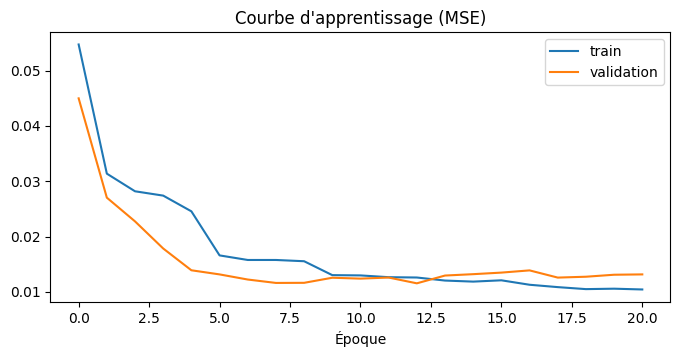

In [5]:
plt.figure(figsize=(8, 3.5))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Courbe d'apprentissage (MSE)"); plt.xlabel("Époque"); plt.legend(); plt.show()

## 4. Évaluation sur le jeu de test (LSTM vs persistance)

In [6]:
results = pd.DataFrame(model.evaluate(test)).T
results

,MAE,RMSE,R2
LSTM,102.487602,147.838040,0.698843
Persistance,64.473480,117.362266,0.810208


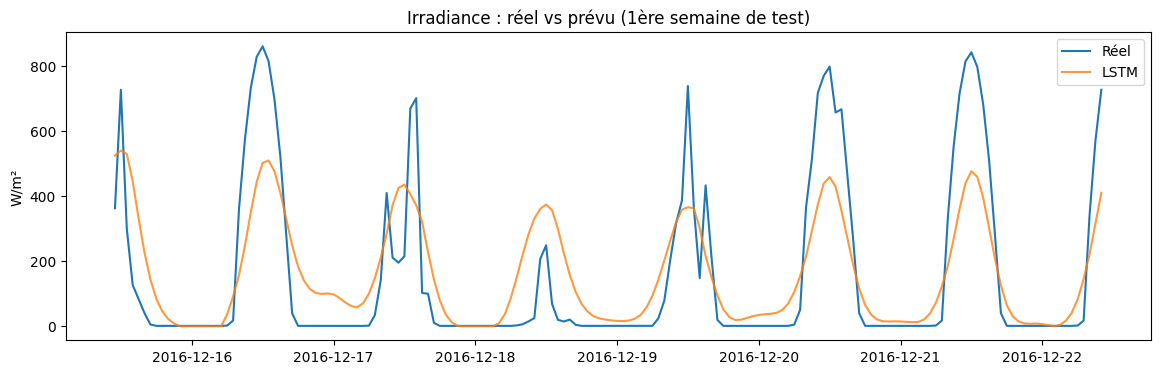

In [7]:
y_true = model.true_values(test)
y_pred = model.predict(test)
idx = model.target_index(test)

N = 24 * 7   # une semaine
plt.figure(figsize=(14, 4))
plt.plot(idx[:N], y_true[:N, 0], label="Réel")
plt.plot(idx[:N], y_pred[:N, 0], label="LSTM", alpha=0.8)
plt.title("Irradiance : réel vs prévu (1ère semaine de test)")
plt.ylabel("W/m²"); plt.legend(); plt.show()

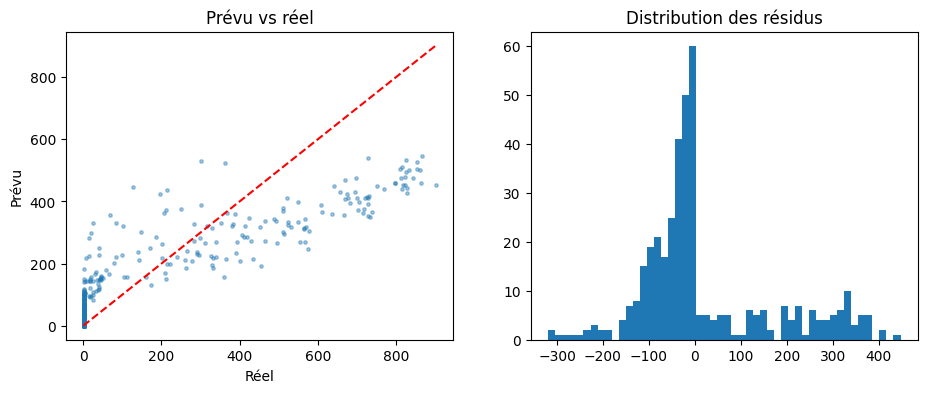

In [8]:
# Nuage de points prédit vs réel + résidus
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_true[:, 0], y_pred[:, 0], s=6, alpha=0.4)
m = max(y_true.max(), y_pred.max()); ax[0].plot([0, m], [0, m], "r--")
ax[0].set_xlabel("Réel"); ax[0].set_ylabel("Prévu"); ax[0].set_title("Prévu vs réel")
ax[1].hist((y_true[:, 0] - y_pred[:, 0]), bins=50)
ax[1].set_title("Distribution des résidus")
plt.show()

## 5. Choix de la configuration (sur la validation)
On compare quelques réglages. Le choix se fait sur le jeu de **validation** : choisir sur le test reviendrait à utiliser le test pour régler le modèle (fuite d'information).

In [9]:
# shuffle : mélanger les fenêtres pendant l'entraînement (les fenêtres restent chronologiques à l'intérieur)
configs = [
    {"window": w, "units": u, "dropout": d, "shuffle": sh}
    for w, u, d in [(6, (32,), 0.1), (12, (32,), 0.1), (24, (64, 32), 0.2), (48, (64, 32), 0.3)]
    for sh in (False, True)
]
rows, models = [], []
for c in configs:
    params = {k: v for k, v in c.items() if k != "shuffle"}
    m = SolarLSTM(horizon=HORIZON, **params)
    m.fit(train, val, epochs=40, verbose=0, shuffle=c["shuffle"])
    rows.append({**{k: str(v) for k, v in c.items()},
                 **{f"val_{k}": v for k, v in m.evaluate(val)["LSTM"].items()}})
    models.append(m)
comparison = pd.DataFrame(rows)
best_i = comparison["val_RMSE"].idxmin()
best_model = models[best_i]
print("Persistance sur la validation :", {k: round(v, 3) for k, v in models[0].evaluate(val)["Persistance"].items()})
print("Configuration retenue :", configs[best_i])
comparison.round(3)

Persistance sur la validation : {'MAE': 48.614, 'RMSE': 92.601, 'R2': 0.819}
Configuration retenue : {'window': 6, 'units': (32,), 'dropout': 0.1, 'shuffle': True}


,window,units,dropout,shuffle,val_MAE,val_RMSE,val_R2
0,6,"(32,)",0.1,False,59.834,100.899,0.785
1,6,"(32,)",0.1,True,54.703,95.149,0.809
2,12,"(32,)",0.1,False,67.532,107.641,0.758
3,12,"(32,)",0.1,True,61.476,104.648,0.771
4,24,"(64, 32)",0.2,False,77.028,118.813,0.707
5,24,"(64, 32)",0.2,True,62.563,109.040,0.753
6,48,"(64, 32)",0.3,False,75.218,123.300,0.682
7,48,"(64, 32)",0.3,True,65.474,111.329,0.741


## 6. Modèle retenu : test et production photovoltaïque estimée
Le jeu de données ne contient que l'irradiance. La production PV est **estimée** avec une formule simple (`estimate_pv_power`) :

$$P_{PV} = P_{crête} \times \frac{G}{1000} \times PR$$

avec $P_{crête}$ = 150 kWc (taille choisie pour le micro-réseau simulé), $G$ l'irradiance en W/m² et $PR$ = 0,8 (pertes). Comme la formule est linéaire, le R² est le même que pour l'irradiance.

,MAE,RMSE,R2
LSTM,68.018,113.329,0.820
Persistance,63.912,117.181,0.807


Production PV estimée (kW) :


,MAE,RMSE,R2
LSTM,8.162,13.600,0.820
Persistance,7.669,14.062,0.807


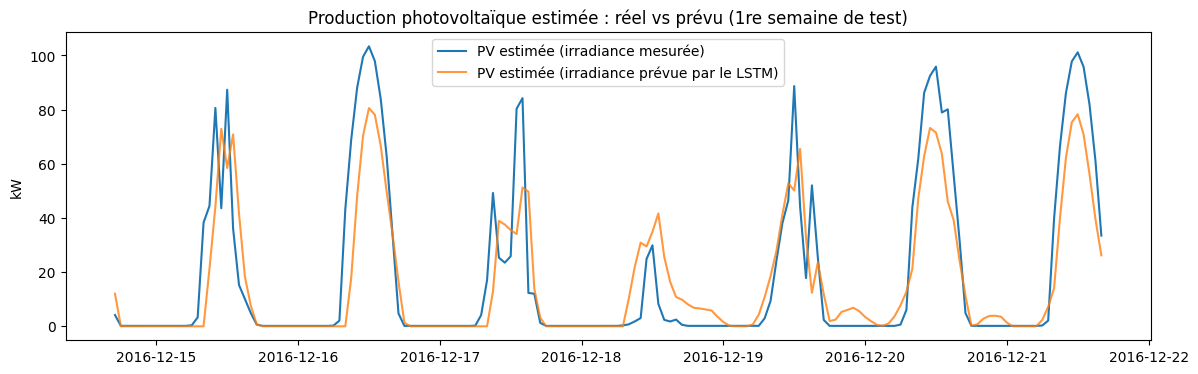

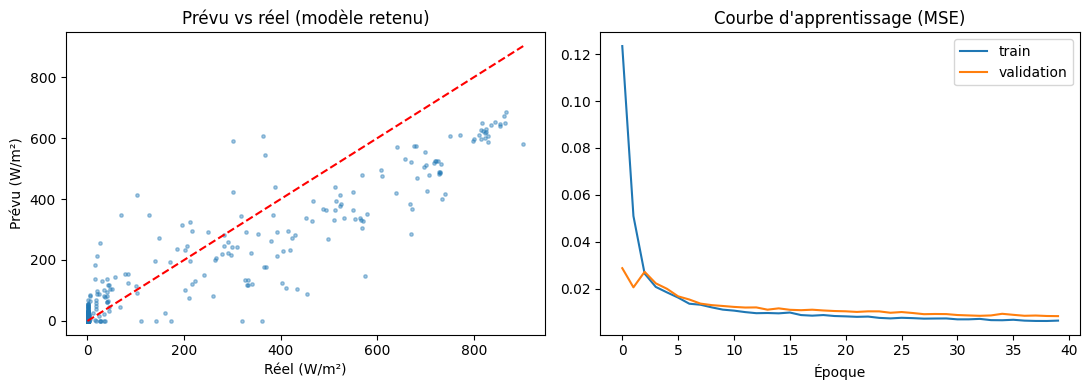

In [10]:
from src.models.lstm_solar import estimate_pv_power

final_results = pd.DataFrame(best_model.evaluate(test)).T
display(final_results.round(3))

rad_true = best_model.true_values(test)[:, 0]
rad_pred = best_model.predict(test)[:, 0]
rad_pers = test["Radiation"].values[best_model.window - 1:-1]
pv_true, pv_pred, pv_pers = (estimate_pv_power(g) for g in (rad_true, rad_pred, rad_pers))
print("Production PV estimée (kW) :")
display(pd.DataFrame({"LSTM": compute_metrics(pv_true, pv_pred),
                      "Persistance": compute_metrics(pv_true, pv_pers)}).T.round(3))

idx = best_model.target_index(test)
N = 24 * 7
plt.figure(figsize=(14, 4))
plt.plot(idx[:N], pv_true[:N], label="PV estimée (irradiance mesurée)")
plt.plot(idx[:N], pv_pred[:N], label="PV estimée (irradiance prévue par le LSTM)", alpha=0.8)
plt.title("Production photovoltaïque estimée : réel vs prévu (1re semaine de test)")
plt.ylabel("kW"); plt.legend()
plt.savefig("../reports/figures/lstm_pv_pred_vs_real.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(rad_true, rad_pred, s=6, alpha=0.4)
m = max(rad_true.max(), rad_pred.max()); ax[0].plot([0, m], [0, m], "r--")
ax[0].set_xlabel("Réel (W/m²)"); ax[0].set_ylabel("Prévu (W/m²)"); ax[0].set_title("Prévu vs réel (modèle retenu)")
ax[1].plot(best_model.history.history["loss"], label="train"); ax[1].plot(best_model.history.history["val_loss"], label="validation")
ax[1].set_title("Courbe d'apprentissage (MSE)"); ax[1].set_xlabel("Époque"); ax[1].legend()
plt.tight_layout(); plt.savefig("../reports/figures/lstm_scatter_learning.png", dpi=150); plt.show()

## 7. Sauvegarde du modèle retenu (utilisé par la pipeline)

In [11]:
best_model.save("../models_saved", "lstm_solar")
loaded = SolarLSTM.load("../models_saved", "lstm_solar")
print(loaded.evaluate(test)["LSTM"])

{'MAE': 68.018310546875, 'RMSE': 113.32949403729816, 'R2': 0.8196300864219666}


## Conclusions
- Premier modèle (fenêtre 24 h, 2 couches LSTM) : R² = 0,70 sur le test, **moins bon que la persistance** (R² = 0,81).
- Choix sur la validation : fenêtre 6 h, une couche de 32 unités, fenêtres mélangées pendant l'entraînement. Mélanger les fenêtres améliore toutes les configurations.
- Modèle retenu, sur le test (14 → 31 déc. 2016) : **MAE = 68 W/m², RMSE = 113 W/m², R² = 0,820**, contre MAE = 64, RMSE = 117, R² = 0,807 pour la persistance. Le LSTM fait **à peu près jeu égal** avec la persistance : légèrement meilleur en RMSE, légèrement moins bon en MAE.
- Production PV **estimée** (150 kWc, PR = 0,8) : RMSE = 13,6 kW pour le LSTM contre 14,1 kW pour la persistance.
- Explications possibles : seulement 4 mois de données (≈ 2 000 heures d'entraînement), test en fin décembre (soleil plus bas qu'à l'entraînement) et horizon d'1 heure, où la persistance est très difficile à battre.
- Pistes : horizon de 24 h (où la persistance d'1 h n'est plus possible), plus de données, météo prévue en entrée.
- Précision : une première sélection sans mélange donnait R² = 0,694 sur le test ; la fenêtre de 6 h et le mélange ont été ajoutés après des essais où les scores de test étaient visibles. Le score final est donc probablement un peu optimiste.